# C23 — Laboratório de Inteligência Artificial
## Aula: Análise Exploratória de Dados (EDA)

**Objetivo da aula:** compreender como uma análise exploratória ajuda a conhecer um conjunto de dados antes da construção de um modelo de Inteligência Artificial.

### 1. O que é EDA?

A Análise Exploratória de Dados (Exploratory Data Analysis — EDA) é o processo de investigar um conjunto de dados para compreender sua estrutura, qualidade, distribuição e relações entre variáveis.

A EDA não é apenas "fazer gráficos". Ela deve ajudar a responder perguntas sobre os dados e orientar decisões posteriores de modelagem.

### 2. O que devemos procurar?

- **Estrutura:** número de amostras, atributos e tipos de dados.
- **Qualidade:** valores ausentes, duplicidades, inconsistências e valores impossíveis.
- **Distribuição:** concentração, dispersão, assimetria e possíveis outliers.
- **Variáveis categóricas:** categorias existentes e frequência de ocorrência.
- **Relações entre variáveis:** associação entre variáveis e possíveis padrões.
- **Relação com o problema:** quais atributos parecem relevantes para o objetivo da análise?

### 3. Análise univariada e bivariada

**Univariada:** observa uma variável por vez. Exemplos: distribuição de idade, frequência das categorias de classe e medidas de tendência central.

**Bivariada:** observa a relação entre duas variáveis. Exemplos: idade × sobrevivência, tarifa × classe e idade × tarifa.

A escolha do gráfico depende do tipo das variáveis. Histogramas são úteis para variáveis numéricas; gráficos de barras, para categorias; dispersões, para relações entre variáveis numéricas.

### 4. Valores ausentes e outliers

Um valor ausente não é necessariamente um erro. Antes de removê-lo ou substituí-lo, é necessário entender por que ele está ausente e qual consequência a decisão pode produzir.

Da mesma forma, um outlier não deve ser automaticamente removido. Um valor extremo pode representar um erro de medição, uma situação rara ou simplesmente uma característica legítima da população.

### 5. Correlação não significa causalidade

Uma forte associação entre duas variáveis não prova que uma delas cause a outra.

A EDA serve para levantar hipóteses e identificar padrões. A interpretação desses padrões depende do contexto do problema.

### 6. EDA no fluxo de um projeto de IA

Uma sequência típica é:

**Problema → Dados → EDA → Pré-processamento → Modelo → Avaliação → Interpretação**

A EDA acontece antes da modelagem, mas suas descobertas podem fazer com que seja necessário voltar às etapas anteriores.

### Referências

- WICKHAM, H.; GROLEMUND, G. *R for Data Science*. O'Reilly Media, 2017.
- MCKINNEY, W. *Python for Data Analysis*. 3. ed. O'Reilly Media, 2022.
- HAN, J.; KAMBER, M.; PEI, J. *Data Mining: Concepts and Techniques*. 3. ed. Morgan Kaufmann, 2011.


# 2. Prática Guiada

Nesta etapa, vamos realizar uma EDA completa sobre um conjunto de dados real.

Execute as células na ordem e observe não apenas **o resultado**, mas também **o motivo de cada análise**.

O conjunto utilizado será o **Titanic**, que contém informações sobre passageiros do navio e uma variável indicando sua sobrevivência.


In [ ]:
# Importamos as bibliotecas utilizadas durante a análise.
# Pandas será usado para manipulação dos dados.
# NumPy fornece operações numéricas.
# Matplotlib e Seaborn serão usados para visualização.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


In [ ]:
# Carregamos o conjunto de dados.
# O primeiro endereço é a fonte oficial disponibilizada pelo Seaborn.
# Caso o ambiente não consiga acessá-la, utilizamos uma cópia pública como alternativa.
try:
    df = sns.load_dataset("titanic")
except Exception:
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
    df = pd.read_csv(url)

df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
# Antes de calcular estatísticas, precisamos conhecer a estrutura da base.
# shape informa o número de linhas e colunas.
# columns mostra os nomes das variáveis.

print(f"Amostras: {df.shape[0]}")
print(f"Variáveis: {df.shape[1]}")

print("\nVariáveis:")
print(df.columns.tolist())

print("\nSignificado de cada coluna (variável) nas amostras:")
print("- survived: Se o passageiro sobreviveu (1 = sim, 0 = não).")
print("- pclass: Classe do bilhete (1 = 1ª classe, 2 = 2ª classe, 3 = 3ª classe), indicando o nível socioeconômico.")
print("- sex: Gênero do passageiro (male ou female).")
print("- age: Idade do passageiro em anos.")
print("- sibsp: Número de irmãos ou cônjuges a bordo.")
print("- parch: Número de pais ou filhos a bordo.")
print("- fare: Valor da tarifa paga pela passagem.")
print("- embarked: Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton).")
print("- class: A mesma informação de pclass, mas escrita por extenso (First, Second, Third).")
print("- who: Categoria demográfica (man, woman, child).")
print("- adult_male: Se é homem adulto (True ou False).")
print("- deck: O deck (convés) do navio onde ficava a cabine.")
print("- embark_town: Nome completo da cidade do porto de embarque.")
print("- alive: Se está vivo por extenso (yes ou no).")
print("- alone: Se o passageiro estava sozinho sem familiares a bordo (True ou False).")

Amostras: 891
Variáveis: 15

Variáveis:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Significado de cada coluna (variável) nas amostras:
- survived: Se o passageiro sobreviveu (1 = sim, 0 = não).
- pclass: Classe do bilhete (1 = 1ª classe, 2 = 2ª classe, 3 = 3ª classe), indicando o nível socioeconômico.
- sex: Gênero do passageiro (male ou female).
- age: Idade do passageiro em anos.
- sibsp: Número de irmãos ou cônjuges a bordo.
- parch: Número de pais ou filhos a bordo.
- fare: Valor da tarifa paga pela passagem.
- embarked: Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton).
- class: A mesma informação de pclass, mas escrita por extenso (First, Second, Third).
- who: Categoria demográfica (man, woman, child).
- adult_male: Se é homem adulto (True ou False).
- deck: O deck (convés) do navio onde ficava a cabine.
- embark_town: Nome completo da cidade do porto de embar

In [ ]:
# O tipo de dado de cada coluna influencia a análise que podemos realizar.
# Também observamos quantos valores não nulos existem em cada variável.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [ ]:
# Verificamos valores ausentes.
# A quantidade absoluta ajuda a localizar problemas de qualidade.
# A porcentagem facilita a comparação entre colunas.
missing = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": df.isna().mean() * 100
}).sort_values("percentual", ascending=False)

missing


,ausentes,percentual
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


In [ ]:
# Contamos linhas duplicadas.
# Duplicidade pode ser um problema, mas a decisão de removê-la depende do significado
# de uma linha dentro do conjunto de dados.
print(f"Linhas duplicadas: {df.duplicated().sum()}")


Linhas duplicadas: 107


In [ ]:
# Estatísticas descritivas das variáveis numéricas.
# Observe especialmente média, mediana, desvio-padrão, mínimo e máximo.
df.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# Para variáveis categóricas, a contagem de ocorrências é mais informativa.
# Escolhemos algumas variáveis relevantes para observar sua distribuição.
for coluna in ["sex", "class", "embarked", "alone"]:
    print(df[coluna].value_counts(dropna=False))
    print(f"\n")


sex
male      577
female    314
Name: count, dtype: int64


class
Third     491
First     216
Second    184
Name: count, dtype: int64


embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


alone
True     537
False    354
Name: count, dtype: int64




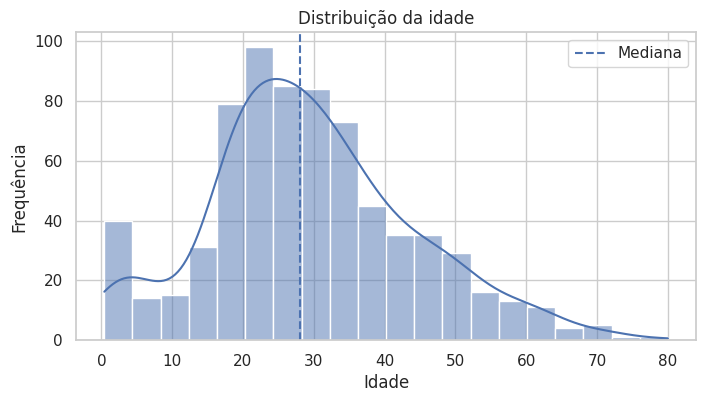

In [ ]:
# Histograma: permite observar a distribuição de uma variável numérica.
# A linha vertical representa a mediana, uma medida menos sensível a valores extremos.
plt.figure(figsize=(8, 4))
sns.histplot(df["age"], bins=20, kde=True)
plt.axvline(df["age"].median(), linestyle="--", label="Mediana")
plt.xlabel("Idade")
plt.ylabel("Frequência")
plt.title("Distribuição da idade")
plt.legend()
plt.show()


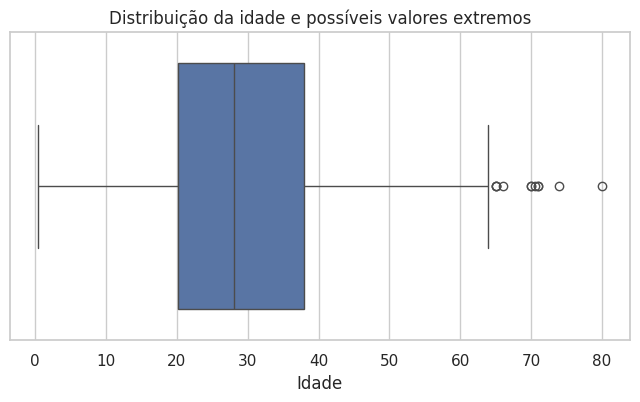

In [ ]:
# Boxplot resume a distribuição e ajuda a identificar valores extremos.
# Um ponto fora dos limites do boxplot não deve ser interpretado automaticamente como erro.
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["age"])
plt.xlabel("Idade")
plt.title("Distribuição da idade e possíveis valores extremos")
plt.show()


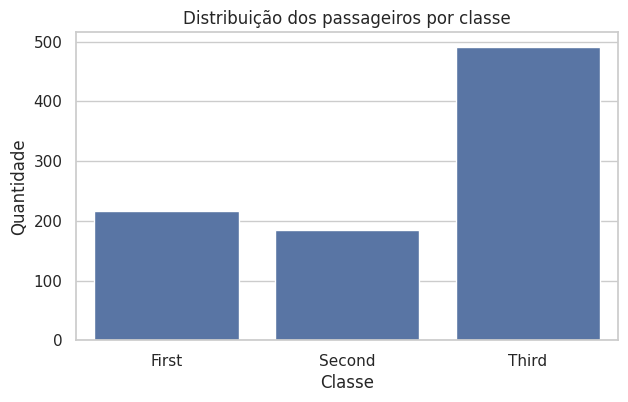

In [ ]:
# Gráfico de barras para uma variável categórica.
# A altura de cada barra representa a quantidade de passageiros em cada classe.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="class")
plt.xlabel("Classe")
plt.ylabel("Quantidade")
plt.title("Distribuição dos passageiros por classe")
plt.show()


In [ ]:
# Agora relacionamos uma variável categórica com a variável de interesse: sobrevivência.

survival_by_class = pd.crosstab(
    df["class"],
    df["survived"],
    normalize="index"
) * 100

survival_by_class.columns = ["Não sobreviveu (%)", "Sobreviveu (%)"]
survival_by_class


,Não sobreviveu (%),Sobreviveu (%)
class,,
First,37.037037,62.962963
Second,52.717391,47.282609
Third,75.763747,24.236253


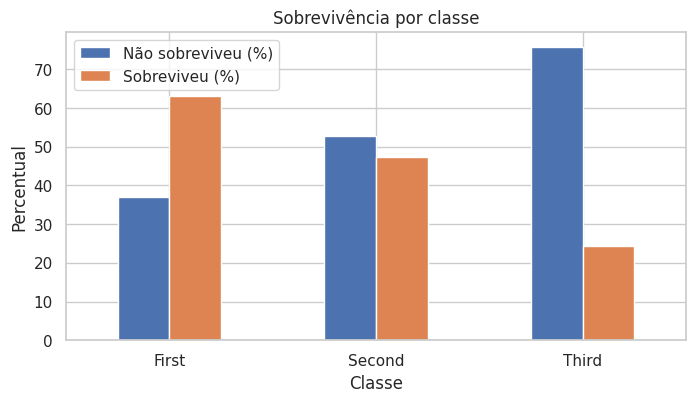

In [ ]:
# Visualizamos a mesma relação para facilitar a interpretação.
survival_by_class.plot(kind="bar", figsize=(8, 4))
plt.xlabel("Classe")
plt.ylabel("Percentual")
plt.title("Sobrevivência por classe")
plt.xticks(rotation=0)
plt.legend()
plt.show()


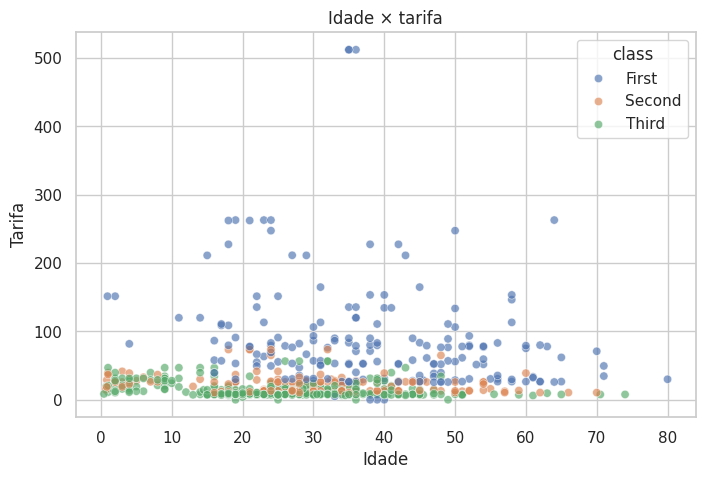

In [ ]:
# Relação entre duas variáveis numéricas.
# Cada ponto representa um passageiro com idade e tarifa observadas.
# A cor representa a classe do passageiro.
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="age",
    y="fare",
    hue="class",
    alpha=0.65
)
plt.xlabel("Idade")
plt.ylabel("Tarifa")
plt.title("Idade × tarifa")
plt.show()


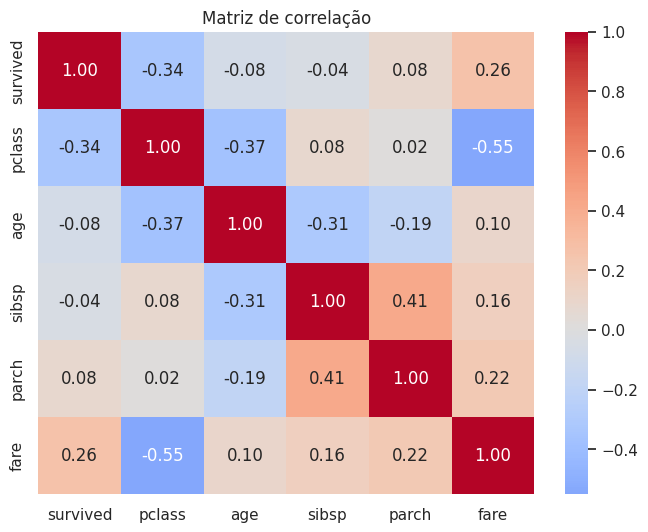

In [ ]:
# Calculamos a matriz de correlação das variáveis numéricas.
# A correlação mede associação linear e não deve ser interpretada como causalidade.
numeric_df = df.select_dtypes(include=np.number)

corr = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação")
plt.show()


In [ ]:
# Uma EDA termina com uma síntese das descobertas.
# Aqui reunimos alguns indicadores que ajudam a revisar o que foi observado.
summary = pd.DataFrame({
    "indicador": [
        "Amostras",
        "Variáveis",
        "Percentual de valores ausentes",
        "Taxa geral de sobrevivência"
    ],
    "valor": [
        len(df),
        df.shape[1],
        round(df.isna().mean().mean() * 100, 2),
        round(df["survived"].mean() * 100, 2)
    ]
})

summary


,indicador,valor
0,Amostras,891.00
1,Variáveis,15.00
2,Percentual de valores ausentes,6.50
3,Taxa geral de sobrevivência,38.38


## Reflexão

Responda às questões abaixo individualmente. Não procure uma "resposta correta" na saída do notebook. O objetivo é justificar suas decisões a partir dos dados observados.

1. Se você tivesse que escolher **uma única variável** para investigar primeiro antes de construir um modelo de sobrevivência, qual escolheria? Justifique usando uma evidência observada na análise.

2. O conjunto possui valores ausentes em algumas variáveis. Escolha **uma delas** e diga qual decisão você tomaria: remover linhas, substituir valores ou manter os dados como estão. Explique por que essa decisão faz sentido **para este problema específico**.

3. Imagine que você encontrou uma associação muito forte entre duas variáveis. Que informação adicional você precisaria conhecer antes de afirmar, em uma apresentação, que uma variável "influencia" a outra?

4. Escolha um passageiro da base que, na sua opinião, seria **difícil de representar adequadamente por um modelo**. Use as características observadas na base para explicar sua escolha.

5. Se o objetivo fosse construir um modelo para prever sobrevivência, qual descoberta desta EDA poderia levar você a **mudar a forma como os dados serão preparados**? Explique o caminho da descoberta até a decisão.

6. Olhando para os gráficos produzidos, indique **uma conclusão que parece convincente visualmente, mas que você não consideraria suficiente para tomar uma decisão de modelagem**. Explique o que faltaria investigar.


# 3. Prática Contextualizada

Na etapa contextualizada, cada aluno deverá aplicar o conteúdo de EDA a um **problema real de sua escolha**.

A apresentação será realizada **na próxima aula**, conforme a organização da disciplina.

### O aluno deverá

- apresentar brevemente o problema que deseja investigar;
- apresentar o dataset escolhido e justificar sua utilização;
- realizar uma EDA adequada ao problema;
- adaptar as técnicas e o código desenvolvidos na prática guiada;
- selecionar resultados relevantes, em vez de apresentar todos os gráficos produzidos;
- interpretar os resultados encontrados;
- explicar quais decisões de pré-processamento ou modelagem poderiam ser tomadas a partir da EDA;
- concluir indicando o que os dados permitem afirmar e quais questões permanecem em aberto.

A apresentação deve demonstrar **compreensão e adaptação**, e não apenas reprodução do notebook desenvolvido em aula.

A atividade será avaliada conforme as regras da **NL2 – Prática Contextualizada**:

- **70% — Professor**
- **30% — Avaliação entre pares**
